In [1]:
# !pip install pystac-client rasterio planetary-computer

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import geopandas as gpd
import rasterio
from shapely.geometry import box
from pystac_client import Client

In [3]:
aoi=box(88.25,22.50,88.45,22.70)
aoi_gdf=gpd.GeoDataFrame({"name":["Kolkata"]},geometry=[aoi],crs="EPSG:4326")
catalog=Client.open("https://planetarycomputer.microsoft.com/api/stac/v1")
print("Connected to STAC API")


Connected to STAC API


In [4]:
# Search Sentinel-2 images
search=catalog.search(
    collections=["sentinel-2-l2a"],
    bbox=[88.25,22.50,88.45,22.70],
    datetime="2025-01-01/2025-03-31",
    query={"eo:cloud_cover": {"lt": 20}})
items=list(search.items())
print("Images found: ", len(items))


Images found:  27


In [5]:
for item in items:
    print(
        item.id,
        item.datetime,
        item.properties.get("eo:cloud_cover"))

S2B_MSIL2A_20250329T043659_R033_T45QXF_20250329T072509 2025-03-29 04:36:59.024000+00:00 0.001191
S2B_MSIL2A_20250329T043659_R033_T45QXE_20250329T072509 2025-03-29 04:36:59.024000+00:00 0.238904
S2C_MSIL2A_20250324T043721_R033_T45QXF_20250324T101805 2025-03-24 04:37:21.025000+00:00 0.00651
S2C_MSIL2A_20250324T043721_R033_T45QXE_20250324T101805 2025-03-24 04:37:21.025000+00:00 1.029754
S2B_MSIL2A_20250319T043709_R033_T45QXF_20250319T072326 2025-03-19 04:37:09.024000+00:00 0.013583
S2A_MSIL2A_20250316T044231_R033_T45QXF_20250316T073801 2025-03-16 04:42:31.024000+00:00 0.00065
S2A_MSIL2A_20250316T044231_R033_T45QXE_20250316T073801 2025-03-16 04:42:31.024000+00:00 0.00361
S2C_MSIL2A_20250314T043721_R033_T45QXF_20250314T074614 2025-03-14 04:37:21.024000+00:00 4.234041
S2C_MSIL2A_20250314T043721_R033_T45QXE_20250314T074614 2025-03-14 04:37:21.024000+00:00 4.806888
S2B_MSIL2A_20250309T043709_R033_T45QXF_20250309T071523 2025-03-09 04:37:09.024000+00:00 3.820296
S2B_MSIL2A_20250309T043709_R033_T

In [6]:
if len(items) == 0:
    raise ValueError("No Sentinel-2 images found for the selected date range and cloud-cover limit.")
item = items[0]
print("Selected scene:", item.id)
print("Date:", item.datetime)
print("Cloud cover:", item.properties.get("eo:cloud_cover"))

Selected scene: S2B_MSIL2A_20250329T043659_R033_T45QXF_20250329T072509
Date: 2025-03-29 04:36:59.024000+00:00
Cloud cover: 0.001191


In [7]:
import planetary_computer
for name in item.assets:
    print(name)
item=planetary_computer.sign(item)
from rasterio.windows import from_bounds
def read_band(item, band_name, aoi):
    url=item.assets[band_name].href
    with rasterio.open(url) as src:
        # Convert AOI bounds to the raster CRS
        aoi_proj=aoi.to_crs(src.crs)
        # Calculate only the window covering the AOI
        window=from_bounds(*aoi_proj.total_bounds, transform=src.transform)
        data=src.read(1, window=window)
        profile=src.profile.copy()
        # Update metadata for the cropped image
        profile.update({
            "height": data.shape[0],
            "width": data.shape[1],
            "transform": src.window_transform(window)
        })
    return data, profile

AOT
B01
B02
B03
B04
B05
B06
B07
B08
B09
B11
B12
B8A
SCL
WVP
visual
safe-manifest
granule-metadata
inspire-metadata
product-metadata
datastrip-metadata
tilejson
rendered_preview


In [8]:
red, profile = read_band(item, "B04", aoi_gdf)
green, _ = read_band(item, "B03", aoi_gdf)
blue, _ = read_band(item, "B02", aoi_gdf)

print("Red:", red.shape)
print("Green:", green.shape)
print("Blue:", blue.shape)

Red: (2080, 2076)
Green: (2080, 2076)
Blue: (2080, 2076)


In [9]:
print("CRS:", profile["crs"])
print("Resolution:", profile["transform"].a, abs(profile["transform"].e))
print("Width:", profile["width"])
print("Height:", profile["height"])

CRS: EPSG:32645
Resolution: 10.0 10.0
Width: 2076
Height: 2080


In [10]:
# Sentinel-2 values to reflectance
red_ref=red.astype("float32")/10000
green_ref=green.astype("float32")/10000
blue_ref=blue.astype("float32")/10000
print("Reflectance conversion complete.")
print("Red range:", red_ref.min(), red_ref.max())
print("Green range:", green_ref.min(), green_ref.max())
print("Blue range:", blue_ref.min(), blue_ref.max())

Reflectance conversion complete.
Red range: 0.1158 0.8832
Green range: 0.1247 0.7652
Blue range: 0.1142 0.8104


RGB shape: (2080, 2076, 3)
RGB dtype: float32


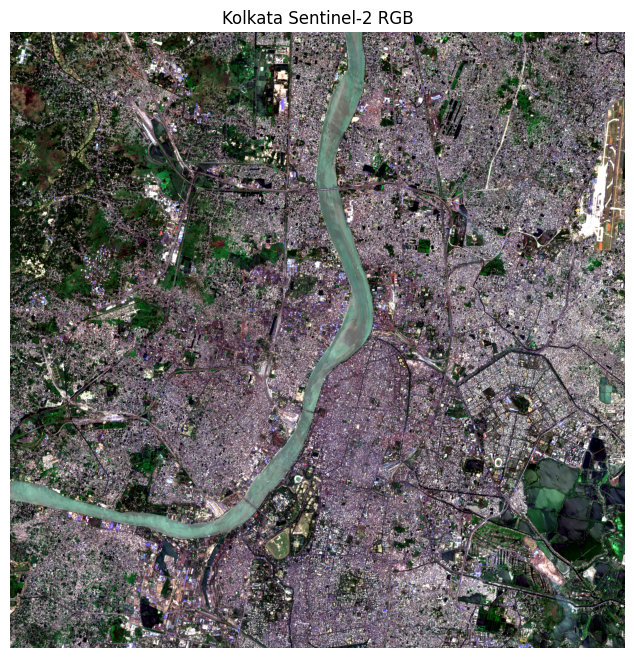

In [11]:
def stretch(x):
    x=np.asarray(x,dtype=np.float32)
    low,high=np.nanpercentile(x,(2,98))
    if high<=low:
        return np.zeros_like(x, dtype=np.float32)
    return np.clip((x-low)/(high-low),0,1).astype(np.float32)
rgb=np.dstack([stretch(red_ref),stretch(green_ref),stretch(blue_ref)]).astype(np.float32)
print("RGB shape:", rgb.shape)
print("RGB dtype:", rgb.dtype)
plt.figure(figsize=(10, 8))
plt.imshow(rgb)
plt.title("Kolkata Sentinel-2 RGB")
plt.axis("off")
plt.show()

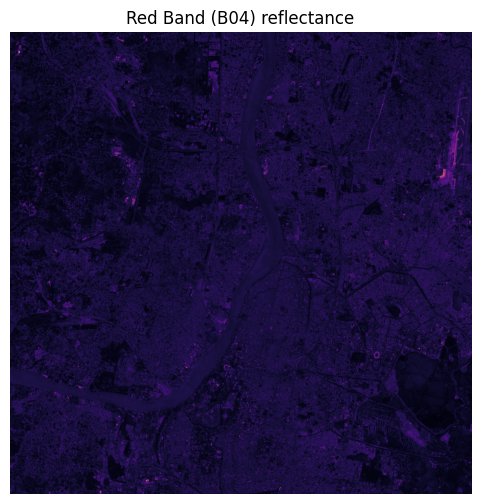

In [12]:
plt.figure(figsize=(7,6))
plt.imshow(red_ref, cmap="magma")
plt.title("Red Band (B04) reflectance")
plt.axis("off")
plt.show()

In [13]:
# Sentinel-2 Scene Classification Layer (SCL)
scl, scl_profile=read_band(item, "SCL", aoi_gdf)
print("SCL shape:", scl.shape)
print("SCL classes:", np.unique(scl))
cloud_classes=[3, 8, 9, 10, 11]
cloud_mask=np.isin(scl,cloud_classes)
print("Cloud/shadow pixels:", cloud_mask.sum())
print("Cloud/shadow percentage:", cloud_mask.mean() * 100)

# 3  → cloud shadow
# 8  → cloud medium probability
# 9  → cloud high probability
# 10 → thin cirrus
# 11 → snow/ice
# these are excluded as the image recorded is when sky was clear and no clouds were present.
# The cloud mask is created to identify and exclude these pixels from further analysis.

SCL shape: (1040, 1038)
SCL classes: [2 4 5 6 7]
Cloud/shadow pixels: 0
Cloud/shadow percentage: 0.0


In [14]:
aoi_gdf.to_file("../data/kolkata_aoi.gpkg", driver="GPKG")
print("AOI saved successfully")

AOI saved successfully
